## chargement et tri par date

In [4]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_arch
from statsmodels.graphics.tsaplots import plot_acf

from src.data_utils import (
    charger_masi,
    nettoyer_masi,
    calculer_rendements,
    decouper_train_test
)

df = charger_masi("../data/raw/masi_historique.csv")

print(df.head())
print(df.dtypes)

        Date     Price      Open      High       Low  Vol. Change %
0 2016-11-11  10551.43  10564.62  10607.58  10532.83   NaN   -0.12%
1 2016-11-14  10577.99  10551.43  10586.46  10550.31   NaN    0.25%
2 2016-11-15  10602.80  10577.99  10610.71  10565.22   NaN    0.23%
3 2016-11-16  10646.95  10602.80  10672.16  10592.36   NaN    0.42%
4 2016-11-17  10697.55  10646.95  10697.55  10632.74   NaN    0.48%
Date        datetime64[ns]
Price              float64
Open               float64
High               float64
Low                float64
Vol.               float64
Change %            object
dtype: object


## nettoyage

In [5]:
print("Avant:", df.shape,df.isna().sum().to_dict())
df=nettoyer_masi(df)
print("Apres:", df.shape,df.isna().sum().to_dict())
df.head()

Avant: (2480, 7) {'Date': 0, 'Price': 0, 'Open': 0, 'High': 0, 'Low': 0, 'Vol.': 2480, 'Change %': 0}
Apres: (2480, 6) {'Date': 0, 'Price': 0, 'Open': 0, 'High': 0, 'Low': 0, 'Change %': 0}


,Date,Price,Open,High,Low,Change %
0,2016-11-11,10551.43,10564.62,10607.58,10532.83,-0.12
1,2016-11-14,10577.99,10551.43,10586.46,10550.31,0.25
2,2016-11-15,10602.80,10577.99,10610.71,10565.22,0.23
3,2016-11-16,10646.95,10602.80,10672.16,10592.36,0.42
4,2016-11-17,10697.55,10646.95,10697.55,10632.74,0.48


## rendements logarithmiques

In [6]:
df=calculer_rendements(df)
df[["Date","Price","ret"]].head()

,Date,Price,ret
0,2016-11-14,10577.99,0.251403
1,2016-11-15,10602.80,0.234269
2,2016-11-16,10646.95,0.415535
3,2016-11-17,10697.55,0.474128
4,2016-11-21,10638.78,-0.550893


## trois graphiques

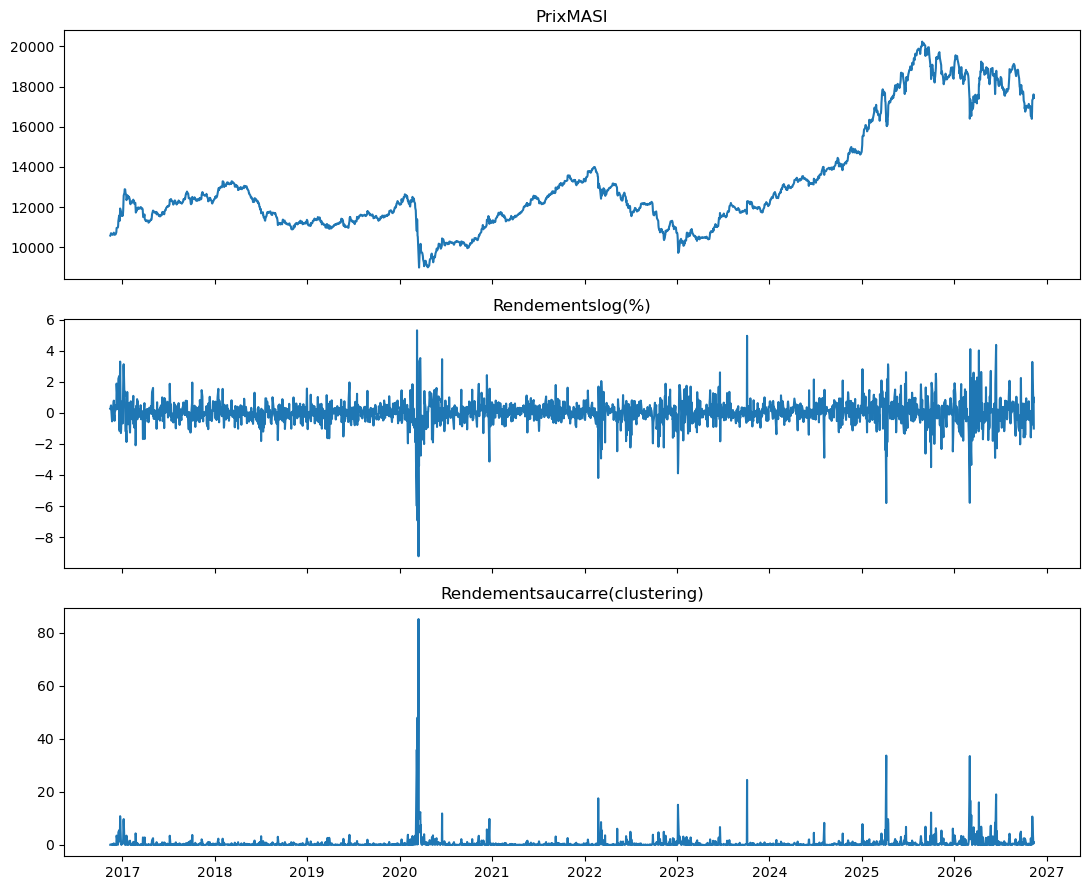

In [7]:
fig,ax=plt.subplots(3,1,figsize=(11, 9),sharex=True)
ax[0].plot(df["Date"], df["Price"]);ax[0].set_title("PrixMASI")
ax[1].plot(df["Date"], df["ret"]);ax[1].set_title("Rendementslog(%)")
ax[2].plot(df["Date"], df["ret"]**2);ax[2].set_title("Rendementsaucarre(clustering)")
plt.tight_layout()
plt.savefig("../figures/a3_graphiques.png",dpi=150)
plt.show()

## statistiques, Jarque-Bera et test d’Engle

2479 2016-11-14 00:00:00 2026-11-11 00:00:00
0.02024687330522036 0.8244770602884289 -0.9915358010695644 15.466373625863568
Jarque-Bera :stat=25006.75, p-valeur=0
Testd’Engle(ARCH-LM,5retards): LM=620.12,p-valeur =9.089e-132


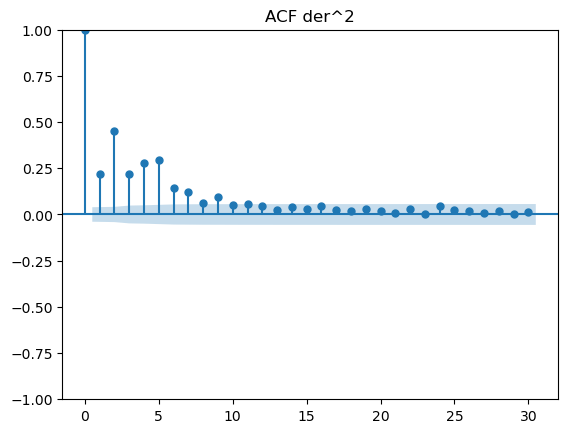

In [8]:
print(len(df),df["Date"].min(),df["Date"].max())
print(df["ret"].mean(), df["ret"].std(),df["ret"].skew(),df["ret"].kurt())
jb_stat,jb_p= jarque_bera(df["ret"])
print(f"Jarque-Bera :stat={jb_stat:.2f}, p-valeur={jb_p:.4g}")
lm,p_lm,f, p_f=het_arch(df["ret"],nlags=5)
print(f"Testd’Engle(ARCH-LM,5retards): LM={lm:.2f},p-valeur ={p_lm:.4g}")
plot_acf(df["ret"] **2,lags=30,title="ACF der^2")
plt.savefig("../figures/acf_r2.png",dpi=150)
plt.show()

## export et découpage train/test (80/20,chronologique)

In [9]:
df[["Date","Price","ret"]].to_csv("../data/processed/rendements.csv",index=False)
train,test= decouper_train_test(df,ratio=0.8)
train.to_csv("../data/processed/train.csv",index=False)
test.to_csv("../data/processed/test.csv",index=False)
print("Train:", len(train),train["Date"].min(), "->",train["Date"].max())
print("Test :",len(test),test["Date"].min(), "->",test["Date"].max())

Train: 1983 2016-11-14 00:00:00 -> 2024-11-01 00:00:00
Test : 496 2024-11-04 00:00:00 -> 2026-11-11 00:00:00
